In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [6]:
# Path to the main dataset
DATASET_PATH = r"C:\ML PROJECT\DATASET"

# Check that the dataset folder exists
print("Dataset path:", DATASET_PATH)
print("Exists:", os.path.exists(DATASET_PATH))

# Show the folders inside DATASET
print("\nContents of DATASET:")
print(os.listdir(DATASET_PATH))

Dataset path: C:\ML PROJECT\DATASET
Exists: True

Contents of DATASET:
['classification', 'Segmentation']


In [7]:
# Check the structure of the dataset

for folder in ["classification", "Segmentation"]:
    folder_path = os.path.join(DATASET_PATH, folder)

    print("\n" + "=" * 50)
    print(folder)
    print("=" * 50)

    for item in os.listdir(folder_path):
        item_path = os.path.join(folder_path, item)

        if os.path.isdir(item_path):
            print("[FOLDER] ", item)
        else:
            print("[FILE]   ", item)


classification
[FOLDER]  Testing
[FOLDER]  Training

Segmentation
[FOLDER]  Glioma
[FOLDER]  Meningioma
[FOLDER]  Pituitary tumor


In [8]:
# Inspect the classification dataset

classification_path = os.path.join(DATASET_PATH, "classification")

for split in ["Training", "Testing"]:
    split_path = os.path.join(classification_path, split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    for item in os.listdir(split_path):
        item_path = os.path.join(split_path, item)

        if os.path.isdir(item_path):
            print("[FOLDER] ", item)
        else:
            print("[FILE]   ", item)


Training
[FOLDER]  glioma
[FOLDER]  meningioma
[FOLDER]  notumor
[FOLDER]  pituitary

Testing
[FOLDER]  glioma
[FOLDER]  meningioma
[FOLDER]  notumor
[FOLDER]  pituitary


In [9]:
# Inspect the segmentation dataset

segmentation_path = os.path.join(DATASET_PATH, "Segmentation")

for tumor_type in os.listdir(segmentation_path):
    tumor_path = os.path.join(segmentation_path, tumor_type)

    if os.path.isdir(tumor_path):
        print("\n" + "=" * 50)
        print(tumor_type)
        print("=" * 50)

        files = os.listdir(tumor_path)

        print("Total files:", len(files))

        # Show the first 10 files
        for file in files[:10]:
            print(file)


Glioma
Total files: 1108
enh_1841.png
enh_1841_mask.png
enh_1842.png
enh_1842_mask.png
enh_1843.png
enh_1843_mask.png
enh_1844.png
enh_1844_mask.png
enh_1845.png
enh_1845_mask.png

Meningioma
Total files: 1416
enh_1.png
enh_10.png
enh_100.png
enh_100_mask.png
enh_101.png
enh_101_mask.png
enh_102.png
enh_102_mask.png
enh_103.png
enh_103_mask.png

Pituitary tumor
Total files: 1860
enh_1000.png
enh_1000_mask.png
enh_1001.png
enh_1001_mask.png
enh_1002.png
enh_1002_mask.png
enh_1003.png
enh_1003_mask.png
enh_1004.png
enh_1004_mask.png


In [10]:
def load_image_and_mask(folder_path, image_file):
    """
    Load an MRI image and its corresponding segmentation mask.
    """
    
    # Create the paths
    image_path = os.path.join(folder_path, image_file)
    mask_file = image_file.replace(".png", "_mask.png")
    mask_path = os.path.join(folder_path, mask_file)
    
    # Load the MRI image
    image = Image.open(image_path).convert("L")
    
    # Load the mask
    mask = Image.open(mask_path).convert("L")
    
    # Convert both to NumPy arrays
    image = np.array(image)
    mask = np.array(mask)
    
    return image, mask

In [11]:
# Select the Glioma folder
glioma_path = os.path.join(segmentation_path, "Glioma")

# Select one MRI image
image_file = "enh_1841.png"

# Load the MRI and its corresponding mask
image, mask = load_image_and_mask(glioma_path, image_file)

# Display basic information
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)

print("\nImage data type:", image.dtype)
print("Mask data type:", mask.dtype)

print("\nImage pixel range:", image.min(), "to", image.max())
print("Mask pixel range:", mask.min(), "to", mask.max())

Image shape: (512, 512)
Mask shape: (512, 512)

Image data type: uint8
Mask data type: uint8

Image pixel range: 1 to 255
Mask pixel range: 3 to 255


In [12]:
# Find the unique pixel values in the mask
unique_values = np.unique(mask)

print("Number of unique mask values:", len(unique_values))
print("Unique mask values:", unique_values)

Number of unique mask values: 2
Unique mask values: [  3 255]


In [13]:
# Convert the segmentation mask into a binary mask
binary_mask = (mask == 255).astype(np.uint8)

# Check the result
print("Unique values in binary mask:", np.unique(binary_mask))
print("Tumor pixels:", np.sum(binary_mask))
print("Background pixels:", np.sum(binary_mask == 0))

Unique values in binary mask: [0 1]
Tumor pixels: 5973
Background pixels: 256171


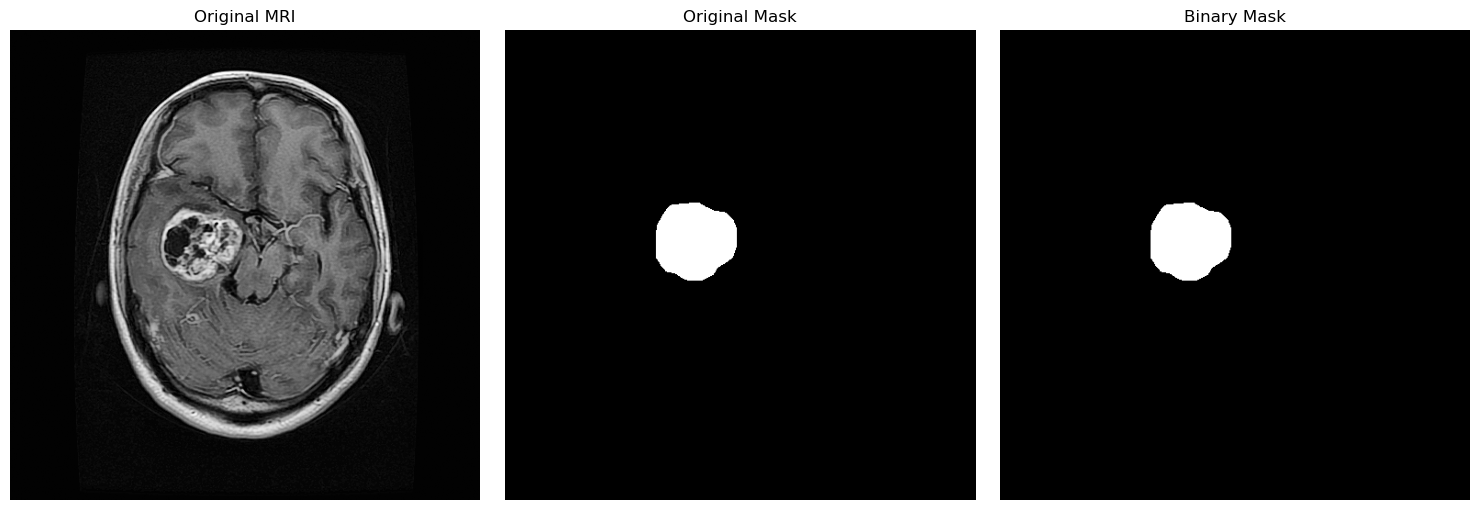

In [14]:
# Visualize the MRI, original mask, and binary mask

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Original MRI
axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original MRI")
axes[0].axis("off")

# Original mask
axes[1].imshow(mask, cmap="gray")
axes[1].set_title("Original Mask")
axes[1].axis("off")

# Binary mask
axes[2].imshow(binary_mask, cmap="gray")
axes[2].set_title("Binary Mask")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Sample image and mask
image_path = r"C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1841.png"
mask_path = r"C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1841_mask.png"

# Load image
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

# Load mask
mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

# Convert mask to binary
binary_mask = (mask == 255).astype(np.uint8)

# Resize image
resized_image = cv2.resize(
    image,
    (256, 256),
    interpolation=cv2.INTER_AREA
)

# Resize mask
resized_mask = cv2.resize(
    binary_mask,
    (256, 256),
    interpolation=cv2.INTER_NEAREST
)

# Normalize image
normalized_image = resized_image / 255.0

# Make sure mask remains binary
resized_mask = (resized_mask > 0).astype(np.uint8)

In [2]:
import sys
print(sys.executable)

C:\ML_PROJECT_ENV\Scripts\python.exe


In [5]:
# Check the resized and normalized sample

print("Original image shape:", image.shape)
print("Resized image shape:", resized_image.shape)

print("Original mask shape:", mask.shape)
print("Resized mask shape:", resized_mask.shape)

print("\nNormalized image range:",
      normalized_image.min(), "to", normalized_image.max())

print("Unique values in resized mask:",
      np.unique(resized_mask))

Original image shape: (512, 512)
Resized image shape: (256, 256)
Original mask shape: (512, 512)
Resized mask shape: (256, 256)

Normalized image range: 0.00392156862745098 to 1.0
Unique values in resized mask: [0 1]


In [11]:
# Apply preprocessing to all segmentation image-mask pairs

import os
import glob
import cv2
import numpy as np

segmentation_path = r"C:\ML PROJECT\DATASET\Segmentation"

processed_images = []
processed_masks = []

# Find all mask files
mask_files = glob.glob(
    os.path.join(segmentation_path, "**", "*_mask.png"),
    recursive=True
)

print("Number of mask files found:", len(mask_files))

for mask_path in mask_files:

    # Corresponding image path
    image_path = mask_path.replace("_mask.png", ".png")

    if not os.path.exists(image_path):
        print("Image not found for:", mask_path)
        continue

    # Load image and mask
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    msk = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if img is None or msk is None:
        print("Could not load:", image_path)
        continue

    # Resize image
    img = cv2.resize(
        img,
        (256, 256),
        interpolation=cv2.INTER_AREA
    )

    # Resize mask
    msk = cv2.resize(
        msk,
        (256, 256),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image
    img = img / 255.0

    # Convert mask to binary
    msk = (msk == 255).astype(np.uint8)

    # Store
    processed_images.append(img)
    processed_masks.append(msk)

processed_images = np.array(processed_images)
processed_masks = np.array(processed_masks)

print("\nPreprocessing completed!")
print("Images shape:", processed_images.shape)
print("Masks shape:", processed_masks.shape)
print("Image value range:",
      processed_images.min(), "to", processed_images.max())
print("Mask unique values:",
      np.unique(processed_masks))

Number of mask files found: 2192

Preprocessing completed!
Images shape: (2192, 256, 256)
Masks shape: (2192, 256, 256)
Image value range: 0.0 to 1.0
Mask unique values: [0 1]


In [12]:
# Check the original mask values

import cv2
import numpy as np

# Check the first few masks
for i in range(min(5, len(mask_files))):
    
    mask_path = mask_files[i]
    original_mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    print(f"\nMask {i + 1}:")
    print("Path:", mask_path)
    print("Shape:", original_mask.shape)
    print("Unique values:", np.unique(original_mask))
    print("Min:", original_mask.min())
    print("Max:", original_mask.max())


Mask 1:
Path: C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1841_mask.png
Shape: (512, 512)
Unique values: [  3 255]
Min: 3
Max: 255

Mask 2:
Path: C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1842_mask.png
Shape: (512, 512)
Unique values: [  3 255]
Min: 3
Max: 255

Mask 3:
Path: C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1843_mask.png
Shape: (512, 512)
Unique values: [  3 255]
Min: 3
Max: 255

Mask 4:
Path: C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1844_mask.png
Shape: (512, 512)
Unique values: [  3 255]
Min: 3
Max: 255

Mask 5:
Path: C:\ML PROJECT\DATASET\Segmentation\Glioma\enh_1845_mask.png
Shape: (512, 512)
Unique values: [  3 255]
Min: 3
Max: 255


In [9]:
# Analyze mask pixel distribution

for i in range(min(5, len(mask_files))):

    mask_path = mask_files[i]
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    values, counts = np.unique(mask, return_counts=True)

    print(f"\nMask {i + 1}:")
    print("File:", os.path.basename(mask_path))

    for value, count in zip(values, counts):
        percentage = (count / mask.size) * 100
        print(
            f"Pixel value {value}: "
            f"{count:,} pixels ({percentage:.2f}%)"
        )


Mask 1:
File: enh_1841_mask.png
Pixel value 3: 256,171 pixels (97.72%)
Pixel value 255: 5,973 pixels (2.28%)

Mask 2:
File: enh_1842_mask.png
Pixel value 3: 255,621 pixels (97.51%)
Pixel value 255: 6,523 pixels (2.49%)

Mask 3:
File: enh_1843_mask.png
Pixel value 3: 256,344 pixels (97.79%)
Pixel value 255: 5,800 pixels (2.21%)

Mask 4:
File: enh_1844_mask.png
Pixel value 3: 258,792 pixels (98.72%)
Pixel value 255: 3,352 pixels (1.28%)

Mask 5:
File: enh_1845_mask.png
Pixel value 3: 252,233 pixels (96.22%)
Pixel value 255: 9,911 pixels (3.78%)


In [14]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.2 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.2 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.2 MB 1.2 MB/s eta 0:00:07
   --- ------------------------------------ 0.8/8.2 MB 1.5 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/8.2 MB 1.5 MB/s eta 0:00:06
   --- ------------------------------------ 0.8/8.2 MB 1.5 MB/s eta 0:00:06
   ----- ---------------------------------- 1.0/8.2 MB 765.9 kB/s eta 0:00:10
   ------ --------------------------------- 1.3/8.2 MB 674.9 kB/s eta 0:00:11
   ------ --------------------------------- 1.3/8.2 MB 674.9 kB/s eta 0:00:11
   ------ --------------------------------- 1.3/8.2 MB 674.9 kB/s eta 0:00:11
   ------- -------------------------------- 1.6/8.2 MB 582.4 kB/s eta 0:00:12
   ------- -------------------------------- 1.6/8.2 MB 582.4 kB/s eta 0:00:12
   ------- -------------------------------- 1.6/8.2 MB 582.4 kB/s eta 0:00:12
   ------- -


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: C:\ML_PROJECT_ENV\Scripts\python.exe -m pip install --upgrade pip


In [15]:
# Split dataset into training, validation, and test sets

from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    processed_images,
    processed_masks,
    test_size=0.30,
    random_state=42
)

# Second split: divide the temporary set equally
# This gives 15% validation and 15% test overall
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print("Dataset split completed!")

print("\nTraining:")
print("Images:", X_train.shape)
print("Masks:", y_train.shape)

print("\nValidation:")
print("Images:", X_val.shape)
print("Masks:", y_val.shape)

print("\nTest:")
print("Images:", X_test.shape)
print("Masks:", y_test.shape)

Dataset split completed!

Training:
Images: (1534, 256, 256)
Masks: (1534, 256, 256)

Validation:
Images: (329, 256, 256)
Masks: (329, 256, 256)

Test:
Images: (329, 256, 256)
Masks: (329, 256, 256)


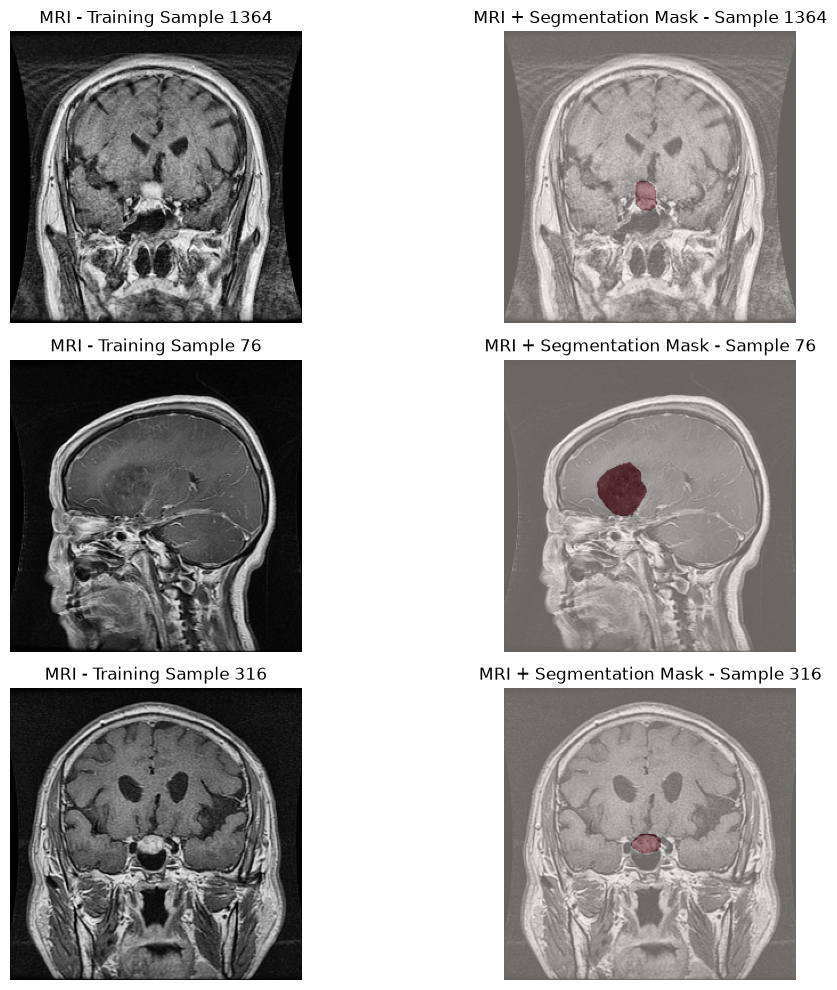

In [16]:
# Visualize random MRI images with their segmentation masks

import matplotlib.pyplot as plt
import numpy as np

# Select 3 random samples
np.random.seed(42)
indices = np.random.choice(len(X_train), 3, replace=False)

plt.figure(figsize=(12, 10))

for i, idx in enumerate(indices):

    # MRI
    plt.subplot(3, 2, 2*i + 1)
    plt.imshow(X_train[idx], cmap="gray")
    plt.title(f"MRI - Training Sample {idx}")
    plt.axis("off")

    # Mask
    plt.subplot(3, 2, 2*i + 2)
    plt.imshow(X_train[idx], cmap="gray")
    plt.imshow(y_train[idx], cmap="Reds", alpha=0.4)
    plt.title(f"MRI + Segmentation Mask - Sample {idx}")
    plt.axis("off")

plt.tight_layout()
plt.show()